In [1]:
!pip install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
statlog_german_credit_data = fetch_ucirepo(id=144) 
  
# data (as pandas dataframes) 
X = statlog_german_credit_data.data.features 
y = statlog_german_credit_data.data.targets 
  
# metadata 
print(statlog_german_credit_data.metadata) 
  
# variable information 
print(statlog_german_credit_data.variables) 


{'uci_id': 144, 'name': 'Statlog (German Credit Data)', 'repository_url': 'https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data', 'data_url': 'https://archive.ics.uci.edu/static/public/144/data.csv', 'abstract': 'This dataset classifies people described by a set of attributes as good or bad credit risks. Comes in two formats (one all numeric). Also comes with a cost matrix', 'area': 'Social Science', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 1000, 'num_features': 20, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Other', 'Marital Status', 'Age', 'Occupation'], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1994, 'last_updated': 'Thu Aug 10 2023', 'dataset_doi': '10.24432/C5NC77', 'creators': ['Hans Hofmann'], 'intro_paper': None, 'additional_info': {'summary': 'Two datasets are provided.  the original dataset, in the form provided by

In [3]:
import sklearn
sklearn.datasets.fetch_openml(name='credit-g', version=1)

{'data':     checking_status  duration                  credit_history  \
 0                <0         6  critical/other existing credit   
 1          0<=X<200        48                   existing paid   
 2       no checking        12  critical/other existing credit   
 3                <0        42                   existing paid   
 4                <0        24              delayed previously   
 ..              ...       ...                             ...   
 995     no checking        12                   existing paid   
 996              <0        30                   existing paid   
 997     no checking        12                   existing paid   
 998              <0        45                   existing paid   
 999        0<=X<200        45  critical/other existing credit   
 
                  purpose  credit_amount    savings_status  employment  \
 0               radio/tv           1169  no known savings         >=7   
 1               radio/tv           5951          

In [4]:
map_checking = {
    'A14': 0,
    'A11': 1,
    'A12': 2,
    'A13': 3
}

map_savings = {
    'A65':0,
    'A61': 1,
    'A62': 2,
    'A63': 3,
    'A64':4
}

map_employment = {
    'A71': 0,
    'A72': 1,
    'A73': 2, 
    'A74': 3,
    'A75': 4
}

map_job = {
    'A171': 0,
    'A172': 1,
    'A173': 2,
    'A174': 3
}

map_history = {
    'A34': 0,
    'A33': 1,
    'A32': 2,
    'A31': 3,
    'A30': 4
}


In [5]:
map_telephone = {
    'A191': 0,
    'A192': 1
}

map_foreign = {
    'A202': 0,
    'A201': 1
}

In [6]:
colunas_nominais = [
    'Attribute4', 
    'Attribute9', 
    'Attribute10', 
    'Attribute12', 
    'Attribute14', 
    'Attribute15'
]

In [7]:
X['Attribute1'] = X['Attribute1'].map(map_checking)
X['Attribute6'] = X['Attribute6'].map(map_savings)
X['Attribute7'] = X['Attribute7'].map(map_employment)
X['Attribute17'] = X['Attribute17'].map(map_job)
X['Attribute3'] = X['Attribute3'].map(map_history)

In [8]:
X['Attribute19'] = X['Attribute19'].map(map_telephone)
X['Attribute20'] = X['Attribute20'].map(map_foreign)

In [9]:
import pandas as pd
X = pd.get_dummies(X, columns=colunas_nominais, dtype=int)

In [10]:
total_nulos = X.isnull().sum().sum()
print(f"Total de valores vazios (NaN) gerados: {total_nulos}")

print(f"\nFormato final da tabela: {X.shape[0]} clientes e {X.shape[1]} atributos")

print("\nTipos de dados presentes na tabela:")
print(X.dtypes.value_counts())

display(X.head())

Total de valores vazios (NaN) gerados: 0

Formato final da tabela: 1000 clientes e 41 atributos

Tipos de dados presentes na tabela:
int64    41
Name: count, dtype: int64


,Attribute1,Attribute2,Attribute3,Attribute5,Attribute6,Attribute7,Attribute8,Attribute11,Attribute13,Attribute16,...,Attribute12_A121,Attribute12_A122,Attribute12_A123,Attribute12_A124,Attribute14_A141,Attribute14_A142,Attribute14_A143,Attribute15_A151,Attribute15_A152,Attribute15_A153
0,1,6,0,1169,0,4,4,4,67,2,...,1,0,0,0,0,0,1,0,1,0
1,2,48,2,5951,1,2,2,2,22,1,...,1,0,0,0,0,0,1,0,1,0
2,0,12,0,2096,1,3,2,3,49,1,...,1,0,0,0,0,0,1,0,1,0
3,1,42,2,7882,1,3,2,4,45,1,...,0,1,0,0,0,0,1,0,0,1
4,1,24,1,4870,1,2,3,4,53,2,...,0,0,0,1,0,0,1,0,0,1


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [14]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate
from sklearn.model_selection import cross_validate

profundidades = [2, 3, 5, 7, 10, None]
acuracias_treino = []
acuracias_validacao = []

for p in profundidades:
    modelo_arvore = DecisionTreeClassifier(max_depth=p, random_state=42)
    cv_resultados = cross_validate(modelo_arvore, X_train, y_train, cv=5, scoring='accuracy', return_train_score=True)
    media_treino = np.mean(cv_resultados['train_score'])
    media_validacao = np.mean(cv_resultados['test_score'])

    acuracias_treino.append(media_treino)
    acuracias_validacao.append(media_validacao)

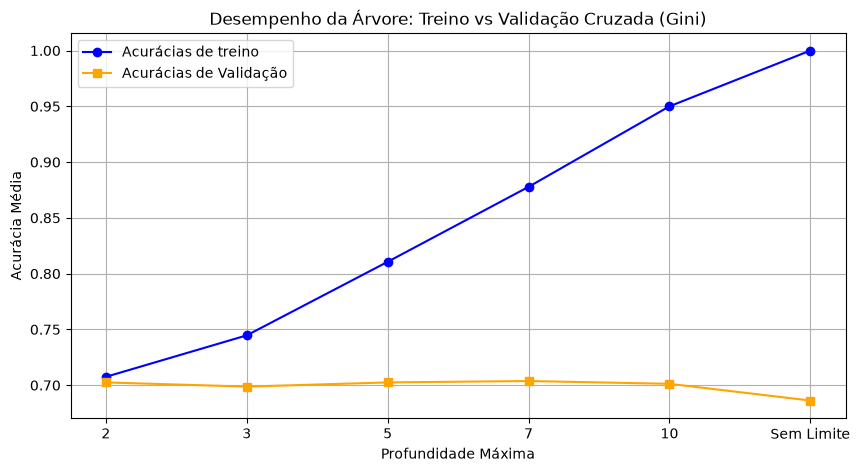

In [15]:
import matplotlib.pyplot as plt

rotulos_x = [str(p) if p is not None else 'Sem Limite' for p in profundidades]
plt.figure(figsize=(10, 5))
plt.plot(rotulos_x, acuracias_treino, marker='o', label='Acurácias de treino', color='blue')
plt.plot(rotulos_x, acuracias_validacao, marker='s', label='Acurácias de Validação', color='orange')
plt.title('Desempenho da Árvore: Treino vs Validação Cruzada (Gini)')
plt.xlabel('Profundidade Máxima')
plt.ylabel('Acurácia Média')
plt.legend()
plt.grid(True)
plt.show()

In [16]:
acuracias_treino_entropia = []
acuracias_validacao_entropia = []

for p in profundidades:
    modelo_arvore_entropia = DecisionTreeClassifier(criterion='entropy', max_depth=p, random_state=42)
    cv_resultados_entropia = cross_validate(modelo_arvore_entropia, X_train, y_train, cv=5, scoring='accuracy', return_train_score=True)
    media_treino_entropia = np.mean(cv_resultados_entropia['train_score'])
    media_validacao_entropia = np.mean(cv_resultados_entropia['test_score'])

    acuracias_treino_entropia.append(media_treino_entropia)
    acuracias_validacao_entropia.append(media_validacao_entropia)

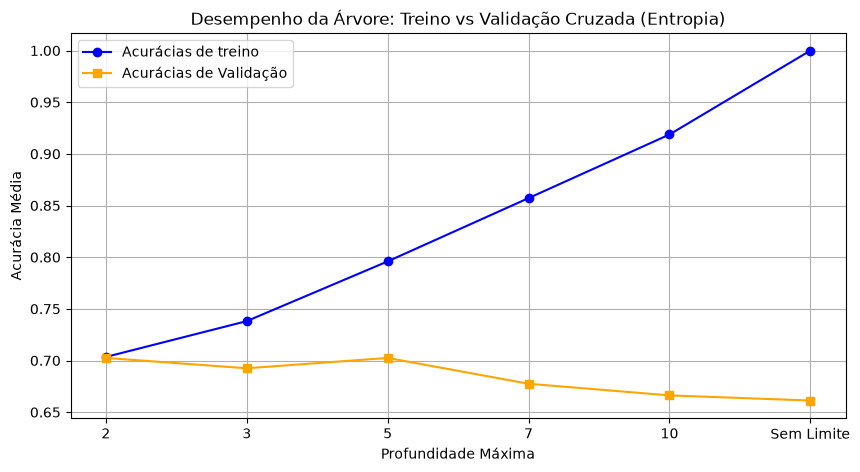

In [17]:
plt.figure(figsize=(10, 5))
plt.plot(rotulos_x, acuracias_treino_entropia, marker='o', label='Acurácias de treino', color='blue')
plt.plot(rotulos_x, acuracias_validacao_entropia, marker='s', label='Acurácias de Validação', color='orange')
plt.title('Desempenho da Árvore: Treino vs Validação Cruzada (Entropia)')
plt.xlabel('Profundidade Máxima')
plt.ylabel('Acurácia Média')
plt.legend()
plt.grid(True)
plt.show()

In [18]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

modelo_final = DecisionTreeClassifier(criterion='gini', max_depth=7,random_state=42)
modelo_final.fit(X_train, y_train)

plt.figure(figsize=(80, 60), dpi=150)
plot_tree(modelo_final, feature_names=X_train.columns, class_names=['Bom pagador (1)', 'Mau pagador (2)'], filled=True, rounded=True, fontsize=8)
plt.title("Visualização da Árvore de Decisão")
plt.savefig("arvore_decisao.svg", format="svg", bbox_inches="tight")
plt.show()

In [19]:
importancias = pd.Series(modelo_final.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(importancias)

Attribute1          0.235191
Attribute5          0.161392
Attribute2          0.111658
Attribute13         0.093805
Attribute3          0.082254
Attribute6          0.056886
Attribute7          0.041006
Attribute4_A46      0.032473
Attribute14_A141    0.032310
Attribute16         0.026640
Attribute8          0.021150
Attribute4_A45      0.019830
Attribute19         0.015372
Attribute12_A124    0.011566
Attribute12_A121    0.011153
Attribute17         0.010416
Attribute10_A101    0.009253
Attribute9_A91      0.008674
Attribute15_A152    0.006990
Attribute9_A94      0.006506
Attribute4_A40      0.005475
Attribute15_A151    0.000000
Attribute14_A143    0.000000
Attribute14_A142    0.000000
Attribute11         0.000000
Attribute10_A102    0.000000
Attribute12_A123    0.000000
Attribute12_A122    0.000000
Attribute10_A103    0.000000
Attribute9_A93      0.000000
Attribute20         0.000000
Attribute9_A92      0.000000
Attribute4_A49      0.000000
Attribute4_A48      0.000000
Attribute18   

In [20]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

y_pred = modelo_final.predict(X_test)

print("Matriz de confusão: \n", confusion_matrix(y_test, y_pred),"\n")
print("Acurácia:", accuracy_score(y_test, y_pred))
print("Métricas por classe:\n")
print(classification_report(
    y_test,
    y_pred,
    labels=[1, 2],
    target_names=['Bom pagador','Mau pagador'],
    digits=4,
    zero_division=0
))

Matriz de confusão: 
 [[102  38]
 [ 24  36]] 

Acurácia: 0.69
Métricas por classe:

              precision    recall  f1-score   support

 Bom pagador     0.8095    0.7286    0.7669       140
 Mau pagador     0.4865    0.6000    0.5373        60

    accuracy                         0.6900       200
   macro avg     0.6480    0.6643    0.6521       200
weighted avg     0.7126    0.6900    0.6980       200

